# The multi-fidelity prior in 1-d: learning curves over a configuration

**What this is.** `priors.mf` is ifBO's FT-PFN prior (Rakotoarison et al., ICML 2024), ported from
Meta_FTPFN (decision 0002). A task is one synthetic HPO problem. A BNN maps a hyperparameter
configuration (here 1-d) to 23 latent outputs. `curves.VectorizedParameterLinker` maps those through
probability-integral transforms to the parameters of a mixture of four learning-curve families (power
law, exponential, logarithmic, Hill): the asymptote, mixture weights, shapes, saturation points and the
noise level. `y0` and `ymax` bound the curves. Similar configurations get similar curves because the
BNN is smooth.

`MFPrior` turns tasks into training episodes, like ifBO: `AllocationPrior` spreads a sequence of tokens
over a few curves. Context tokens observe each curve from its first fidelity level upward (freeze-thaw);
query tokens ask for later fidelities of seen curves, or for new curves. Inputs are `[config, fidelity]`,
and `y = 1 − performance` (this package minimizes).

**How to read this notebook.** Not an experiment: seeded draws in the notebook, to show what the curves
look like, how a context is allocated, and how to use the prior. The first call generates the latent
ECDF for 1 input (about 10 s) and caches it in `data/priors/`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from pfn_repro.priors import build_prior
from pfn_repro.priors.mf import MultiFidelityTask

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(0); torch.manual_seed(0)  # the ported task draws from the global RNGs

## 1. Learning curves of one task

For three tasks: the curves of 12 configurations (colour = configuration value) over fidelity, and the
whole (configuration × fidelity) surface. **What to look for:** curves that rise from y0 and saturate, or
decline after saturation (a post-saturation rate below 1 models divergence or overfitting); shapes
that change with the configuration; crossing curves (the best configuration at low fidelity isn't the
best at high fidelity), which makes freeze-thaw BO non-trivial.

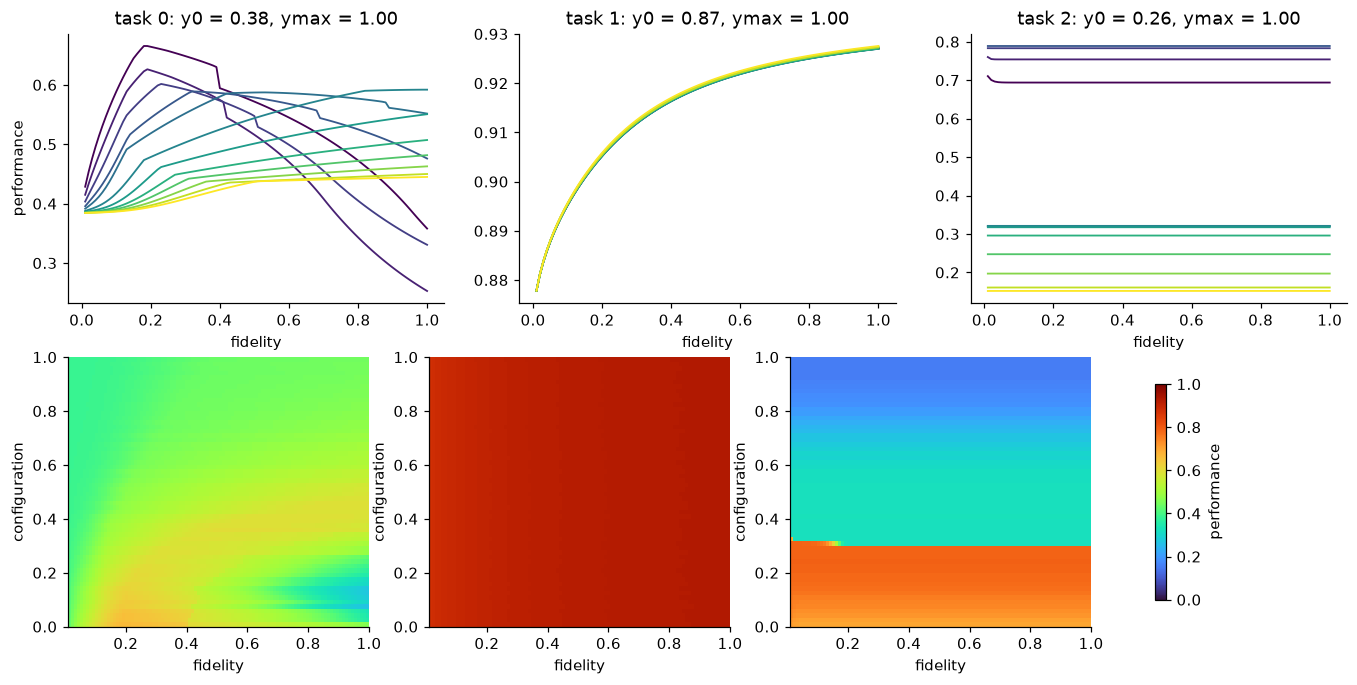

In [ ]:
fid = np.linspace(0.01, 1.0, 100)
configs = torch.linspace(0, 1, 12)[:, None]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for k in range(3):
    task = MultiFidelityTask(num_inputs=1, num_outputs=23); task.sample_task()
    curve = task.get_marginal_curve(configs)
    for i in range(12):
        axes[0, k].plot(fid, curve(fid, cid=i, noise=False), color=plt.cm.viridis(i / 11), lw=1.2)
    axes[0, k].set_title(f"task {k}: y0 = {task.y0:.2f}, ymax = {task.ymax:.2f}"); axes[0, k].set_xlabel("fidelity")
    hp = torch.linspace(0, 1, 60)[:, None]; surf = task.get_marginal_curve(hp)
    Z = np.stack([surf(fid, cid=i, noise=False) for i in range(60)])
    im = axes[1, k].imshow(Z, origin="lower", aspect="auto", extent=(fid[0], 1, 0, 1), cmap="turbo", vmin=0, vmax=1)
    axes[1, k].set_xlabel("fidelity"); axes[1, k].set_ylabel("configuration")
axes[0, 0].set_ylabel("performance"); fig.colorbar(im, ax=axes[1], shrink=0.8, label="performance")
plt.show()

## 2. Noise

The per-task noise level is the linker's sigma (log-normal around e^-5 ≈ 0.007). Observations are
clipped to [0, 1].

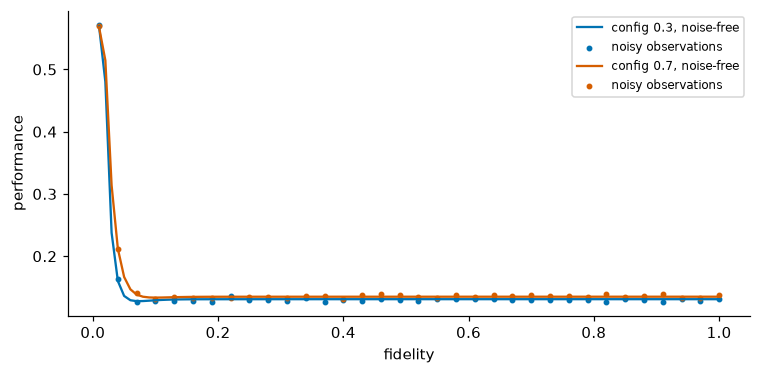

In [ ]:
task = MultiFidelityTask(num_inputs=1, num_outputs=23); task.sample_task()
curve = task.get_marginal_curve(torch.tensor([[0.3], [0.7]]))
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, c in enumerate(("#0072B2", "#D55E00")):
    ax.plot(fid, curve(fid, cid=i, noise=False), color=c, lw=1.5, label=f"config {[0.3, 0.7][i]}, noise-free")
    ax.scatter(fid[::3], curve(fid[::3], cid=i, noise=True), color=c, s=8, label="noisy observations")
ax.set_xlabel("fidelity"); ax.set_ylabel("performance"); ax.legend(fontsize=8); plt.show()

## 3. An episode: how a context is allocated

`MFPrior.sample_episode(n_train, n_test)` for one task (50 fidelity levels). Each colour is one curve
(configuration); circles are context tokens, crosses are queries. **What to look for:** every observed
curve starts at the first fidelity level and is observed contiguously up to its cutoff (freeze-thaw);
queries sit at later fidelities of those curves, or on curves without any observation.

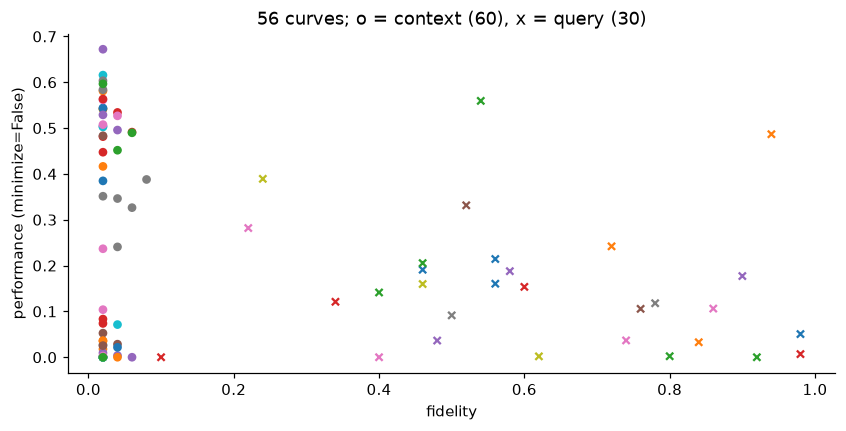

x layout per token: [config, fidelity] -> (1, 60, 2)  n_features = [2]


In [ ]:
prior = build_prior("mf", batch_size=1, x_dim=1, seed=3, variable_dim_min=None, n_levels=50, minimize=False)
x_tr, y_tr, x_te, y_te = prior.sample_episode(60, 30)
cfg_tr, f_tr, cfg_te, f_te = x_tr[0, :, 0], x_tr[0, :, 1], x_te[0, :, 0], x_te[0, :, 1]
ids = {float(c): i for i, c in enumerate(sorted(set(cfg_tr.tolist()) | set(cfg_te.tolist())))}
cols = plt.cm.tab10(np.linspace(0, 1, 10))
fig, ax = plt.subplots(figsize=(9, 4))
for c, f, y, m in ((cfg_tr, f_tr, y_tr[0], "o"), (cfg_te, f_te, y_te[0], "x")):
    ax.scatter(f, y, c=[cols[ids[float(v)] % 10] for v in c], marker=m, s=22)
ax.set_xlabel("fidelity"); ax.set_ylabel("performance (minimize=False)")
ax.set_title(f"{len(ids)} curves; o = context ({x_tr.shape[1]}), x = query ({x_te.shape[1]})"); plt.show()
print("x layout per token: [config, fidelity] ->", tuple(x_tr.shape), " n_features =", prior.active_dim.tolist())

## 4. Usage

```python
from pfn_repro.priors import build_prior
prior = build_prior("mf", batch_size=64, x_dim=3, seed=0)   # up to 3 hyperparameters + fidelity
x_tr, y_tr, x_te, y_te = prior.sample_episode(n_train=50, n_test=100)   # y = 1 - performance
```

To train a surrogate on it: `uv run pfn_repro experiment=train_smoke prior=mf surrogate=tabpfn` (scratch),
or a tracked sweep. No MF checkpoint is registered yet.

**What we see.**
- **Tasks vary a lot in difficulty.**
  - Task 0 has the interesting structure: low configurations rise fast and then decline after
    saturation, high ones rise slowly and keep improving, so the curves cross and the ranking at
    fidelity 0.2 is the reverse of the one at 1.0.
  - Task 1 is nearly degenerate: all configurations give the same curve.
  - Task 2's curves saturate almost at once, at levels that are piecewise constant in the
    configuration (a step near 0.3).

  These come from the PIT mapping of the BNN's latent outputs: a flat stretch of the BNN gives one
  set of curve parameters.
- **Kinks** at a curve's saturation point (task 0) come from the saturation transform's change of
  slope. They are part of ifBO's prior, not a plotting artifact.
- **Noise.** It is small (sigma around 0.005 here). A curve can also fall from its start: the noise
  example declines from 0.57 to 0.13 within the first 10% of fidelity, i.e. immediate divergence.
- **Allocation.** With 90 tokens and 50 levels, this episode spreads over 56 curves. Most observed
  curves have one to four contiguous observations from the first level. Queries sit at scattered later
  fidelities, many on curves without any observation, which is what ifBO's allocation produces with
  its Dirichlet-like weights.